# Lecture 4: A Two-Agent New Keynesian Economy

**Lecture 4 of 9** · [Series index](README.md)

*This lecture extends [Lecture 3: Sticky Prices, the Output Gap and Monetary Policy](03_sticky_prices.ipynb), which builds on [Lecture 2: Cass-Koopmans with Capital and Labour Adjustment Costs](02_adjustment_costs.ipynb) and [Lecture 1: Cass-Koopmans Competitive Equilibrium — solved with Newton's method](01_cass_koopmans_competitive_equilibrium.ipynb). The series adapts [Cass-Koopmans Competitive Equilibrium](https://python.quantecon.org/cass_koopmans_2.html) by Thomas J. Sargent and John Stachurski (QuantEcon, [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)) and is shared under the same licence. The Newton solver used throughout is adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html), also licensed under CC BY-SA 4.0.*

## Overview

Every model so far has had a single representative household. It owns the capital stock and the firm, smooths consumption through an Euler equation, and responds to interest rates through intertemporal substitution. In [Lecture 3](03_sticky_prices.ipynb) that one Euler equation carried almost all of monetary transmission.

Heterogeneous-agent New Keynesian (HANK) models replace that household with many households facing uninsurable income risk. A central finding of that literature, for example Kaplan, Moll and Violante (2018), is that monetary policy then works mostly **indirectly**. A rate cut raises demand, demand raises incomes, and households with high marginal propensities to consume spend that extra income. The direct effect of interest rates on consumption is small.

A full HANK model needs a distribution of wealth and a household block of its own. This lecture takes the simplest step in that direction, a **two-agent (TANK)** economy in the spirit of Campbell and Mankiw (1989), Galí, López-Salido and Vallés (2007) and Bilbiie (2008):

- a share $\lambda$ of households are **hand-to-mouth**: they hold no assets, receive no profits and consume their wage income every period, and
- the remaining $1 - \lambda$ are **savers**, who own the firm and the capital stock and behave exactly like the representative household of the earlier lectures.

Everything else — firms, capital and labour adjustment costs, the Phillips curve, the policy rule with the output gap, and the cost-push shock — is carried over from [Lecture 3](03_sticky_prices.ipynb). With $\lambda = 0$ the model is exactly that lecture's economy.

We ask how the hand-to-mouth share changes three things:

1. **who drives the response of consumption** to monetary policy,
2. **who bears a cost-push shock**, and
3. how the **trade-off** between inflation and the output gap looks when it is also a choice about distribution.

In [1]:
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from collections import namedtuple

jax.config.update("jax_enable_x64", True)

## Building blocks from the earlier lectures

This section collects, without further comment, the code the TANK model uses from [Lecture 3](03_sticky_prices.ipynb), which derives and explains it:

- Newton's method (adapted from QuantEcon's [Using Newton's Method to Solve Economic Models](https://python.quantecon.org/newton_method.html)) and the adjustment-cost functions,
- the flexible-price economy of [Lecture 2](02_adjustment_costs.ipynb) (functions prefixed `lab_`), which provides the representative-agent benchmark,
- the sticky-price settings, price block and starting guess, and
- the representative-agent gap model, renamed `get_gap_settings`, `gap_transition_economy` and `run_gap` here so the TANK model can use the plain names. We use it to check that the TANK model with $\lambda = 0$ reproduces it.

In [2]:
def newton(f, x_0, tol=1e-5, max_iter=15, adj=1, verbose=False):
    # A multivariate Newton root-finding routine.
    x = x_0
    f_jac = jax.jacobian(f)

    @jax.jit
    def q(x, adj):
        # Updates the current guess.
        return x - adj * jnp.linalg.solve(f_jac(x), f(x))

    error = 1e10
    n = 0
    while error > tol:
        n += 1
        if n > max_iter:
            print('Max iteration reached without convergence')
            return x
        y = q(x, adj)
        error = jnp.linalg.norm(x - y)
        x = y
        if verbose:
            print(f'iteration {n}, error = {error}')
    return x


# ----- capital adjustment cost;  k = (k_0..k_{T+1}),  output indexed t = 0..T -----
def adjustment_cost(k, s):
    # AC_t = zeta k_t/2 (k_{t+1}/k_t - 1)^2, paid in goods
    return s.zeta * k[:-1] / 2 * (k[1:] / k[:-1] - 1) ** 2


# ----- labour adjustment costs;  n_ext = (n_{-1}, n_0..n_T),  outputs indexed t = 0..T -----
def labour_adj_cost(n_ext, s):
    return s.zeta_n * n_ext[1:] / 2 * (n_ext[1:] / n_ext[:-1] - 1) ** 2


def labour_adj_cost_prime_t(n_ext, s):
    # dLAC_t / dn_t
    g = n_ext[1:] / n_ext[:-1]
    return s.zeta_n / 2 * (g - 1) ** 2 + s.zeta_n * g * (g - 1)


def labour_adj_cost_prime_t1(n_ext, s):
    # dLAC_t / dn_{t-1}
    g = n_ext[1:] / n_ext[:-1]
    return -s.zeta_n * (g - 1) * g ** 2


def lead(z):
    # z_{t+1}, with z_{T+1} = 0 (no labour adjustment after T)
    return jnp.concatenate([z[1:], jnp.zeros(1)])

In [3]:
LabSettings = namedtuple('LabSettings', ['beta', 'gamma', 'delta', 'alpha', 'A', 'T', 'k0', 'zeta',
                                         'zeta_n', 'H', 'a', 'n0', 'k_ss', 'n_ss', 'c_ss'])


def get_lab_settings(beta=0.95, gamma=2.0, delta=0.02, alpha=0.33, A=1.0, T=200, k0_frac=0.3,
                     zeta=5.0, zeta_n=2.0, H=1.0, n_target=1 / 3):
    # Steady state has employment n_ss = n_target * H; the consumption weight a is calibrated to deliver it.
    kappa = ((1 / beta - (1 - delta)) / (alpha * A)) ** (1 / (alpha - 1))      # k/n in steady state
    y_n = A * kappa ** alpha
    c_n = y_n - delta * kappa
    w_ss = (1 - alpha) * y_n
    n_ss = n_target * H
    a = 1 / (1 + (H - n_ss) / n_ss * w_ss / c_n)
    k_ss, c_ss = kappa * n_ss, c_n * n_ss
    return LabSettings(beta, gamma, delta, alpha, A, T, k0_frac * k_ss, zeta, zeta_n, H, a, n_ss, k_ss, n_ss, c_ss)


def lab_MLAC(n_ext, p_y, s, r):
    p_next = jnp.concatenate([p_y[1:], p_y[-1:]])
    return (p_y * labour_adj_cost_prime_t(n_ext, s)
            + p_next * lead(labour_adj_cost_prime_t1(n_ext, s)) / (1 + r))


def lab_unpack(x, s):
    T, n = s.T, s.T + 1
    p_y = jnp.concatenate([jnp.ones(1), jnp.exp(x[:T])])
    w, u, y, nl = (jnp.exp(x[T + i * n:T + (i + 1) * n]) for i in range(4))
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[T + 4 * n:]), jnp.array([s.k_ss])])
    return p_y, w, u, y, nl, k


def lab_price_block(p_y, w, u, y, nl, k, s, r):
    ac = adjustment_cost(k, s)
    ks = k[:-1]
    n_ext = jnp.concatenate([jnp.array([s.n0]), nl])
    lac = labour_adj_cost(n_ext, s)
    mlac = lab_MLAC(n_ext, p_y, s, r)
    y_bt = y + ac + lac
    p_n = w + mlac
    p_y_bt = p_n * nl / ((1 - s.alpha) * y_bt)
    p_ks = p_y_bt * s.alpha * y_bt / ks
    p_c = p_i = p_y
    p_l = w
    p_u = (p_c / s.a) ** s.a * (p_l / (1 - s.a)) ** (1 - s.a)
    c = s.a * p_u * u / p_c
    leisure = (1 - s.a) * p_u * u / p_l
    invest = k[1:] - (1 - s.delta) * k[:-1]
    q = p_i + p_y * s.zeta * (invest / ks - s.delta)
    return dict(ac=ac, lac=lac, mlac=mlac, y_bt=y_bt, p_n=p_n, p_y_bt=p_y_bt, p_ks=p_ks, p_c=p_c, p_i=p_i,
                p_l=p_l, p_u=p_u, c=c, l=leisure, N_supply=s.H - leisure, I=invest, q=q)


def lab_transition_economy(x, s, solving=1):
    p_y, w, u, y, nl, k = lab_unpack(x, s)
    r = 1 / s.beta - 1
    P = lab_price_block(p_y, w, u, y, nl, k, s, r)
    price_error = (p_y - P['p_y_bt']) / p_y
    production_error = jnp.log(P['y_bt']) - jnp.log(s.A * k[:-1] ** s.alpha * nl ** (1 - s.alpha))
    labour_error = (P['N_supply'] - nl) / nl
    goods_error = (P['c'] + P['I'] - y) / y
    household_error = (jnp.log(u[1:]) - jnp.log(u[:-1])
                       - (1 / s.gamma) * jnp.log(s.beta * (1 + r) * P['p_u'][:-1] / P['p_u'][1:]))
    ik, q = P['I'] / k[:-1], P['q']
    r_implied = (P['p_ks'][1:] + 0.5 * s.zeta * p_y[1:] * (ik[1:] ** 2 - s.delta ** 2)
                 + (1 - s.delta) * q[1:] - q[:-1]) / q[:-1]
    errors = jnp.concatenate([price_error, production_error, labour_error, goods_error,
                              household_error, r_implied - r])
    if solving:
        return errors
    econ = dict(P, p_y=p_y, w=w, u=u, y=y, n=nl, k=k, r=r,
                real_w=w / P['p_c'], r_real=(1 + r) * p_y[:-1] / p_y[1:] - 1)
    return errors, econ


def lab_initial_guess(s):
    n = s.T + 1
    kappa = s.k_ss / s.n_ss
    y_ss = s.A * kappa ** s.alpha * s.n_ss
    w_ss = (1 - s.alpha) * y_ss / s.n_ss
    u_ss = s.c_ss ** s.a * (s.H - s.n_ss) ** (1 - s.a)
    k_path = np.linspace(s.k0, s.k_ss, s.T + 2)[1:-1]
    return np.log(np.hstack((np.ones(s.T), w_ss * np.ones(n), u_ss * np.ones(n), y_ss * np.ones(n),
                             s.n_ss * np.ones(n), k_path)))


def run_flexible(**kwargs):
    s = get_lab_settings(**kwargs)
    f = lambda x: lab_transition_economy(x, s, 1)
    x1 = newton(f, lab_initial_guess(s), tol=1e-6, max_iter=1000, adj=0.3)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1)
    errors, econ = lab_transition_economy(x, s, 0)
    return s, {k_: np.asarray(v) for k_, v in econ.items()}

In [4]:
StickySettings = namedtuple('StickySettings', list(LabSettings._fields) + ['eps', 'tau_s', 'zeta_p', 'phi_pi'])


def get_sticky_settings(eps=6.0, zeta_p=50.0, phi_pi=1.5, **kwargs):
    # kwargs go to the labour model's settings (T, k0_frac, zeta, zeta_n, ...)
    s0 = get_lab_settings(**kwargs)
    return StickySettings(*s0, eps, 1 / (eps - 1), zeta_p, phi_pi)


def MLAC_nominal(n_ext, p, i_ext, s):
    # p_t dLAC_t/dn_t + p_{t+1}/(1+i_t) dLAC_{t+1}/dn_t  -- MLAC with a time-varying nominal rate
    p_next = jnp.concatenate([p[1:], p[-1:]])
    return (p * labour_adj_cost_prime_t(n_ext, s)
            + p_next * lead(labour_adj_cost_prime_t1(n_ext, s)) / (1 + i_ext))


def price_block(p, i_ext, w, u, y, nl, k, s):
    ac = adjustment_cost(k, s)
    ks = k[:-1]
    n_ext = jnp.concatenate([jnp.array([s.n0]), nl])
    lac = labour_adj_cost(n_ext, s)
    mlac = MLAC_nominal(n_ext, p, i_ext, s)

    p_prev = jnp.concatenate([jnp.ones(1), p[:-1]])
    pi = p / p_prev                                                   # inflation, p_{-1} = 1
    pac = s.zeta_p / 2 * (pi - 1) ** 2 * y                            # price adjustment cost (final goods)

    y_bt = y + ac + lac                                               # output produced
    p_n = w + mlac                                                    # price of labour input
    p_y_bt = p_n * nl / ((1 - s.alpha) * y_bt)                        # nominal marginal cost
    p_ks = p_y_bt * s.alpha * y_bt / ks                               # capital services price
    mc = p_y_bt / p                                                   # real marginal cost
    p_c, p_i, p_l = p, p, w

    p_u = (p_c / s.a) ** s.a * (p_l / (1 - s.a)) ** (1 - s.a)
    c = s.a * p_u * u / p_c
    leisure = (1 - s.a) * p_u * u / p_l
    N_supply = s.H - leisure

    invest = k[1:] - (1 - s.delta) * k[:-1]
    q = p_i + p * s.zeta * (invest / ks - s.delta)
    return dict(ac=ac, lac=lac, mlac=mlac, pac=pac, pi=pi, y_bt=y_bt, p_n=p_n, p_y_bt=p_y_bt, p_ks=p_ks, mc=mc,
                p_c=p_c, p_i=p_i, p_l=p_l, p_u=p_u, c=c, l=leisure, N_supply=N_supply, I=invest, q=q)

In [5]:
def benchmark(**kwargs):
    # Flexible-price economy (the labour model). Its real interest rate path is the natural rate r^n_t.
    s_lab, econ_b = run_flexible(**kwargs)
    return econ_b


def guess_from_benchmark(s, econ_b):
    # Zero inflation (p = 1), i_t = r^n_t, real allocation = benchmark; w is then the real wage.
    T = s.T
    return np.log(np.hstack((np.ones(T + 1), 1 + econ_b['r_real'], econ_b['real_w'], econ_b['u'], econ_b['y'],
                             econ_b['n'], econ_b['k'][1:T + 1])))

In [6]:
GapSettings = namedtuple('GapSettings', list(StickySettings._fields) + ['phi_x'])


def get_gap_settings(phi_x=0.5, **kwargs):
    # kwargs go to get_sticky_settings (eps, zeta_p, phi_pi) and the labour model (T, k0_frac, ...)
    s0 = get_sticky_settings(**kwargs)
    return GapSettings(*s0, phi_x)


def markup_shock(eps, m):
    # Elasticity path eps_t that raises the desired markup by m_t (log points): M_t = eps/(eps-1) e^{m_t}
    M = eps / (eps - 1) * np.exp(np.asarray(m))
    return M / (M - 1)


def unpack(x, s):
    T, n = s.T, s.T + 1
    p = jnp.exp(x[:n])
    ri = jnp.exp(x[n:n + T])
    w, u, y, nl, n_pot = (jnp.exp(x[n + T + j * n:n + T + (j + 1) * n]) for j in range(5))
    k = jnp.concatenate([jnp.array([s.k0]), jnp.exp(x[n + T + 5 * n:]), jnp.array([s.k_ss])])
    return p, ri, w, u, y, nl, n_pot, k


def gap_transition_economy(x, s, rn, nu, eps_t, solving=1):
    p, ri, w, u, y, nl, n_pot, k = unpack(x, s)
    T = s.T
    i = ri - 1
    i_ext = jnp.concatenate([i, i[-1:]])
    P = price_block(p, i_ext, w, u, y, nl, k, s)
    pi = P['pi']
    pi_next = jnp.concatenate([pi[1:], jnp.ones(1)])
    y_next = jnp.concatenate([y[1:], y[-1:]])
    ks = k[:-1]

    # potential employment for the current capital stock (mc = 1, holding k, u and the labour-adjustment wedge)
    gap = (1 - s.alpha) * (jnp.log(nl) - jnp.log(n_pot))
    lhs = (1 - s.a) / s.a * (u / (s.H - n_pot)) ** (1 / s.a) + P['mlac'] / p
    rhs = (1 - s.alpha) * s.A * ks ** s.alpha * n_pot ** (-s.alpha)
    potential_error = jnp.log(lhs) - jnp.log(rhs)

    phillips_error = ((1 + s.tau_s) * (1 - eps_t) + eps_t * P['mc'] - s.zeta_p * (pi - 1) * pi
                      + s.zeta_p * (pi_next - 1) * pi_next ** 2 * (y_next / y) / (1 + i_ext))
    production_error = jnp.log(P['y_bt']) - jnp.log(s.A * ks ** s.alpha * nl ** (1 - s.alpha))
    labour_error = (P['N_supply'] - nl) / nl
    goods_error = (P['c'] + P['I'] + P['pac'] - y) / y

    sigma = 1 / s.gamma
    household_error = (jnp.log(u[1:]) - jnp.log(u[:-1])
                       - sigma * jnp.log(s.beta * ri * P['p_u'][:-1] / P['p_u'][1:]))

    ik, q = P['I'] / ks, P['q']
    r_implied = (P['p_ks'][1:] + 0.5 * s.zeta * p[1:] * (ik[1:] ** 2 - s.delta ** 2)
                 + (1 - s.delta) * q[1:] - q[:-1]) / q[:-1]
    capital_error = r_implied - i

    rule_error = jnp.log(ri) - (jnp.log(1 + rn) + s.phi_pi * jnp.log(pi[:T]) + s.phi_x * gap[:T] + nu[:T])
    terminal_error = jnp.log(pi[T:])

    errors = jnp.concatenate([phillips_error, production_error, labour_error, goods_error, household_error,
                              capital_error, rule_error, terminal_error, potential_error])
    if solving:
        return errors

    div = (1 + s.tau_s) * p * y - w * nl - P['p_i'] * P['I'] - p * P['pac']
    div_factor = (P['p_ks'] * ks + P['mlac'] * nl - P['p_y_bt'] * (P['ac'] + P['lac'])
                  - P['p_i'] * P['I'] - p * P['pac'] + ((1 + s.tau_s) * p - P['p_y_bt']) * y)
    budget = P['p_c'] * P['c'] - (w * nl + div_factor - s.tau_s * p * y)
    econ = dict(P, p=p, i=i, w=w, u=u, y=y, n=nl, n_pot=n_pot, gap=gap, k=k, div=div, budget=budget,
                div_gap=div - div_factor, real_w=w / p, r_real=ri[:T] / pi[1:] - 1, nu=nu, eps_t=eps_t)
    return errors, econ


def guess(s, econ_b):
    # Flexible-price (zero inflation) guess with n_pot = n; potential unknowns sit just before k.
    g = guess_from_benchmark(s, econ_b)
    cut = (s.T + 1) + s.T + 4 * (s.T + 1)
    return np.hstack((g[:cut], np.log(econ_b['n']), g[cut:]))


def run_gap(econ_b, nu=None, markup=None, damp=0.3, verbose=True, **kwargs):
    # Solve the sticky economy with the gap rule. `markup` is the cost-push shock path m_t (log points).
    s = get_gap_settings(**kwargs)
    nu = jnp.zeros(s.T + 1) if nu is None else jnp.asarray(nu)
    eps_t = jnp.asarray(np.full(s.T + 1, s.eps) if markup is None else markup_shock(s.eps, markup))
    rn = jnp.asarray(econ_b['r_real'])
    f = lambda x: gap_transition_economy(x, s, rn, nu, eps_t, 1)
    x0 = guess(s, econ_b)
    if verbose:
        print(f'residual at the flexible-price guess = {float(jnp.max(jnp.abs(f(x0)))):.2e}')
    x1 = newton(f, x0, tol=1e-6, max_iter=1000, adj=damp)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1)
    errors, econ = gap_transition_economy(x, s, rn, nu, eps_t, 0)
    econ = {k_: np.asarray(v) for k_, v in econ.items()}
    if verbose:
        print(f'max |error block| = {float(jnp.max(jnp.abs(errors))):.2e}   '
              f'max |Walras budget| = {np.max(np.abs(econ["budget"])):.2e}')
    return s, econ

## The two-agent economy

### Hand-to-mouth households

A share $\lambda$ of households have no assets and receive no profit income. Each period they choose consumption $c_{H,t}$ and leisure $l_{H,t} = H - n_{H,t}$ to maximise the same Cobb-Douglas composite as everyone else, $c^a l^{1-a}$, subject to spending exactly what they earn:

$$
p_t\, c_{H,t} = w_t\, n_{H,t}
$$

With Cobb-Douglas preferences the household spends a fixed share $a$ of its **full income** $w_t H$ on consumption and $1-a$ on leisure. So

$$
n_{H,t} = aH, \qquad c_{H,t} = aH\, \frac{w_t}{p_t}
$$

Two features of this matter for everything that follows:

- **Their hours never move.** A higher real wage makes work more attractive (the substitution effect) but also makes them richer (the income effect), and with Cobb-Douglas preferences and no other income the two exactly cancel.
- **Their consumption moves one-for-one with the real wage.** Their marginal propensity to consume out of wage income is one, and interest rates do not affect them directly at all.

### Savers

The remaining $1 - \lambda$ households are savers. They own the firm, so they receive all dividends, and they pay the lump-sum tax that funds the production subsidy, so for them the subsidy is a wash. They choose their utility path through the same Euler equation as the representative household of the earlier lectures, and split it between consumption and leisure in the same way. Their per-person budget is

$$
p_t\, c_{S,t} = w_t\, n_{S,t} + \frac{d_t - \tau_s p_t y_t}{1 - \lambda}
$$

where $d_t$ is total dividends. Like the household budget before, it holds by Walras' law, and we report it as a check.

### Aggregation and the steady state

Aggregate consumption and employment are

$$
C_t = \lambda c_{H,t} + (1-\lambda)\, c_{S,t}, \qquad N_t = \lambda n_{H,t} + (1-\lambda)\, n_{S,t}
$$

The savers' Euler equation still pins down $r = 1/\beta - 1$ and the capital-labour ratio, so the aggregate steady state is unchanged. Aggregate hours are unchanged too, because everyone has the same Cobb-Douglas preferences and spends a share $1-a$ of full income on leisure. That gives $N = aH - (1-a)D$, where $D = d/w$ is steady-state dividends in wage units, whatever $\lambda$ is. So the consumption weight $a$ keeps its representative-agent value.

What changes with $\lambda$ is who does what. Hand-to-mouth households work $aH$, more than average, because they have no dividend income. Savers work less, $n_S = aH - (1-a)D/(1-\lambda)$, because each saver receives $1/(1-\lambda)$ times the average dividend. That requires $\lambda$ small enough to keep $n_S$ positive.

### Potential employment

As in [Lecture 3](03_sticky_prices.ipynb), potential employment is where real marginal cost would be one, holding fixed the capital stock, the savers' utility index $u_{S,t}$ and the labour-adjustment wedge. At $mc = 1$, the firm pays the real wage

$$
w^r = (1-\alpha) A k_t^\alpha n^{-\alpha} - \frac{MLAC_t}{p_t}
$$

Aggregate labour supply at that wage now has two parts. Hand-to-mouth hours are fixed at $aH$. Savers' leisure follows from their Cobb-Douglas demand, holding $u_{S,t}$ fixed:

$$
N^s(w^r) = \lambda\, aH + (1-\lambda)\left(H - u_{S,t} \left(\frac{1-a}{a\, w^r}\right)^{a}\right)
$$

Potential employment solves $n^{pot}_t = N^s\!\left(w^r(n^{pot}_t)\right)$, and the gap is again $x_t = (1-\alpha)(\ln n_t - \ln n^{pot}_t)$.

Because a share $\lambda$ of the workforce does not respond to wages, **aggregate labour supply becomes less elastic as $\lambda$ rises**. That one fact explains several of the results below.

### The stacked system

The unknowns have the same layout as the gap model, $8T + 6$ of them, with $u_t$ now the savers' utility index. The equations change in three places:

- the **labour market** clears aggregate labour supply $\lambda n_H + (1-\lambda) n_S$,
- the **goods market** uses aggregate consumption $C_t$, and
- the **potential-employment** condition uses the two-part labour supply above.

In [7]:
TankSettings = namedtuple('TankSettings', list(GapSettings._fields) + ['lam'])


def get_settings(lam=0.3, **kwargs):
    # lam = share of hand-to-mouth households; other kwargs as in get_gap_settings.
    # `a` keeps its representative-agent value: aggregate hours in steady state do not depend on lam.
    s0 = get_gap_settings(**kwargs)
    return TankSettings(*s0, lam)


def transition_economy(x, s, rn, nu, eps_t, solving=1):
    p, ri, w, u, y, nl, n_pot, k = unpack(x, s)
    T, lam = s.T, s.lam
    i = ri - 1
    i_ext = jnp.concatenate([i, i[-1:]])
    P = price_block(p, i_ext, w, u, y, nl, k, s)                       # P['c'], P['N_supply'] are the savers'
    pi = P['pi']
    pi_next = jnp.concatenate([pi[1:], jnp.ones(1)])
    y_next = jnp.concatenate([y[1:], y[-1:]])
    ks = k[:-1]

    w_r = w / p
    c_S, n_S = P['c'], P['N_supply']
    c_H = s.a * s.H * w_r
    n_H = s.a * s.H * jnp.ones_like(w_r)
    C = lam * c_H + (1 - lam) * c_S
    N_agg = lam * n_H + (1 - lam) * n_S

    # potential employment for the current capital stock
    gap = (1 - s.alpha) * (jnp.log(nl) - jnp.log(n_pot))
    w_r_pot = (1 - s.alpha) * s.A * ks ** s.alpha * n_pot ** (-s.alpha) - P['mlac'] / p
    l_S_pot = u * ((1 - s.a) / (s.a * w_r_pot)) ** s.a
    N_pot = lam * s.a * s.H + (1 - lam) * (s.H - l_S_pot)
    potential_error = jnp.log(n_pot) - jnp.log(N_pot)

    phillips_error = ((1 + s.tau_s) * (1 - eps_t) + eps_t * P['mc'] - s.zeta_p * (pi - 1) * pi
                      + s.zeta_p * (pi_next - 1) * pi_next ** 2 * (y_next / y) / (1 + i_ext))
    production_error = jnp.log(P['y_bt']) - jnp.log(s.A * ks ** s.alpha * nl ** (1 - s.alpha))
    labour_error = (N_agg - nl) / nl
    goods_error = (C + P['I'] + P['pac'] - y) / y

    sigma = 1 / s.gamma
    household_error = (jnp.log(u[1:]) - jnp.log(u[:-1])
                       - sigma * jnp.log(s.beta * ri * P['p_u'][:-1] / P['p_u'][1:]))

    ik, q = P['I'] / ks, P['q']
    r_implied = (P['p_ks'][1:] + 0.5 * s.zeta * p[1:] * (ik[1:] ** 2 - s.delta ** 2)
                 + (1 - s.delta) * q[1:] - q[:-1]) / q[:-1]
    capital_error = r_implied - i

    rule_error = jnp.log(ri) - (jnp.log(1 + rn) + s.phi_pi * jnp.log(pi[:T]) + s.phi_x * gap[:T] + nu[:T])
    terminal_error = jnp.log(pi[T:])

    errors = jnp.concatenate([phillips_error, production_error, labour_error, goods_error, household_error,
                              capital_error, rule_error, terminal_error, potential_error])
    if solving:
        return errors

    div = (1 + s.tau_s) * p * y - w * nl - P['p_i'] * P['I'] - p * P['pac']
    div_factor = (P['p_ks'] * ks + P['mlac'] * nl - P['p_y_bt'] * (P['ac'] + P['lac'])
                  - P['p_i'] * P['I'] - p * P['pac'] + ((1 + s.tau_s) * p - P['p_y_bt']) * y)
    tax = s.tau_s * p * y
    budget = p * C - (w * nl + div_factor - tax)                                  # aggregate Walras check
    budget_S = p * c_S - (w * n_S + (div_factor - tax) / (1 - lam)) if lam < 1 else 0 * budget   # per-saver budget
    econ = dict(P, p=p, i=i, w=w, u=u, y=y, n=nl, n_pot=n_pot, gap=gap, k=k, div=div, budget=budget,
                budget_S=budget_S, div_gap=div - div_factor, real_w=w_r, r_real=ri[:T] / pi[1:] - 1, nu=nu,
                eps_t=eps_t, c=C, c_H=c_H, c_S=c_S, n_H=n_H, n_S=n_S, N_agg=N_agg)
    return errors, econ

### Solving: the natural economy first

The rule is anchored on the natural real rate, and the natural rate now belongs to the flexible-price **TANK** economy, not the representative-agent one. So each experiment starts by solving the flexible ($\zeta_p = 0$) TANK economy without shocks. Its real rate anchors the rule, and its allocation is the starting guess for the sticky-price runs.

The flexible TANK economy itself starts from the representative-agent solution, splitting consumption and hours into the two types.

In [8]:
def _solve(s, x0, rn, nu, eps_t, damp, verbose):
    f = lambda x: transition_economy(x, s, rn, nu, eps_t, 1)
    if verbose:
        print(f'residual at the starting guess = {float(jnp.max(jnp.abs(f(x0)))):.2e}')
    x1 = newton(f, x0, tol=1e-6, max_iter=1000, adj=damp)
    x = newton(f, x1, tol=1e-12, max_iter=100, adj=1)
    errors, econ = transition_economy(x, s, rn, nu, eps_t, 0)
    econ = {k_: np.asarray(v) for k_, v in econ.items()}
    econ['residual'] = float(jnp.max(jnp.abs(errors)))
    if verbose:
        print(f'max |error block| = {econ["residual"]:.2e}   '
              f'max |Walras budget| = {np.max(np.abs(econ["budget"])):.2e}   '
              f'max |saver budget| = {np.max(np.abs(econ["budget_S"])):.2e}')
    return econ


def guess_from_rep(s, e):
    # Starting guess from the representative-agent flexible economy e: split c and n into H and S parts.
    T = s.T
    w_r = e['real_w']
    c_H = s.a * s.H * w_r
    c_S = (e['c'] - s.lam * c_H) / (1 - s.lam)
    n_S = (e['n'] - s.lam * s.a * s.H) / (1 - s.lam)
    u_S = c_S ** s.a * (s.H - n_S) ** (1 - s.a)
    return np.log(np.hstack((np.ones(T + 1), 1 + e['r_real'], w_r, u_S, e['y'], e['n'], e['n'], e['k'][1:T + 1])))


def natural_economy(econ_rep, damp=0.3, verbose=True, **kwargs):
    # Flexible-price (zeta_p = 0) TANK economy: provides the natural real rate path and the starting guess.
    kwargs = dict(kwargs, zeta_p=0.0)
    s = get_settings(**kwargs)
    nu = jnp.zeros(s.T + 1)
    eps_t = jnp.asarray(np.full(s.T + 1, s.eps))
    return _solve(s, guess_from_rep(s, econ_rep), jnp.asarray(econ_rep['r_real']), nu, eps_t, damp, verbose)


def run_tank(econ_nat, nu=None, markup=None, damp=0.3, verbose=True, **kwargs):
    # Sticky TANK economy with the gap rule. econ_nat is natural_economy(...) for the same lam and settings.
    s = get_settings(**kwargs)
    nu = jnp.zeros(s.T + 1) if nu is None else jnp.asarray(nu)
    eps_t = jnp.asarray(np.full(s.T + 1, s.eps) if markup is None else markup_shock(s.eps, markup))
    econ = _solve(s, guess(s, econ_nat), jnp.asarray(econ_nat['r_real']), nu, eps_t, damp, verbose)
    return s, econ

## The economies we compare

We use the experiments of [Lecture 3](03_sticky_prices.ipynb): the economy starts in steady state ($k_0 = k_{ss}$, $T = 100$), with $\zeta = 5$, $\zeta_n = 2$ and the gap rule ($\phi_\pi = 1.5$, $\phi_x = 0.5$). We compare hand-to-mouth shares of $\lambda = 0$, $0.25$ and $0.5$.

In [9]:
kw = dict(zeta=5.0, zeta_n=2.0, k0_frac=1.0, T=100)
lams = (0.0, 0.25, 0.5)
t = np.arange(kw['T'] + 1)

econ_rep = benchmark(**kw)
nats = {lam: natural_economy(econ_rep, lam=lam, verbose=False, **kw) for lam in lams}

print(f'{"":10s}{"c_H":>8s}{"c_S":>8s}{"n_H":>8s}{"n_S":>8s}{"C":>8s}{"N":>8s}')
for lam in lams:
    e = nats[lam]
    print(f'lam = {lam:<4g}' + ''.join(f'{e[key][0]:8.4f}' for key in ('c_H', 'c_S', 'n_H', 'n_S', 'c', 'n')))

               c_H     c_S     n_H     n_S       C       N
lam = 0     0.5708  0.6387  0.4042  0.3333  0.6387  0.3333
lam = 0.25  0.5708  0.6613  0.4042  0.3097  0.6387  0.3333
lam = 0.5   0.5708  0.7066  0.4042  0.2625  0.6387  0.3333


Aggregate consumption and hours are the same in all three economies. Splitting the households changes only who consumes and works. Hand-to-mouth households work more and consume less than savers, and the gap widens with $\lambda$ as the same dividends are shared among fewer savers. (With $\lambda = 0$ there are no hand-to-mouth households; the $c_H$ and $n_H$ columns then show what one would do.)

### Check: $\lambda = 0$ is Lecture 3's economy

With no hand-to-mouth households, the TANK model should reproduce the representative-agent gap model exactly. We check this with the monetary shock from Lecture 3.

In [10]:
nu = -0.01 * 0.7 ** t
m = 0.05 * 0.7 ** t

_, e_ra = run_gap(econ_rep, nu=nu, verbose=False, **kw)
s0, e_tank0 = run_tank(nats[0.0], nu=nu, lam=0.0, **kw)
for key in ('c', 'n', 'k', 'pi', 'i', 'gap'):
    print(f'max |{key} TANK(lam=0) - RA gap model| = {np.max(np.abs(e_tank0[key] - e_ra[key])):.1e}')

residual at the starting guess = 1.00e-02


max |error block| = 2.86e-14   max |Walras budget| = 1.11e-15   max |saver budget| = 1.44e-15
max |c TANK(lam=0) - RA gap model| = 3.3e-16
max |n TANK(lam=0) - RA gap model| = 2.2e-16
max |k TANK(lam=0) - RA gap model| = 2.7e-15
max |pi TANK(lam=0) - RA gap model| = 5.6e-16
max |i TANK(lam=0) - RA gap model| = 6.7e-16
max |gap TANK(lam=0) - RA gap model| = 7.4e-16


## A monetary policy shock

We apply the same 100-basis-point cut to the rule's intercept, $\nu_t = -0.01 \times 0.7^t$, for each $\lambda$. All quantities are shown as deviations from each economy's own steady state, since the two types consume different amounts. A monetary shock leaves the natural rate unchanged, so the real-rate panel compares each economy with its no-shock natural rate.

We go in two steps: first how the shock works in the representative-agent economy ($\lambda = 0$), then what changes when some households are hand-to-mouth.

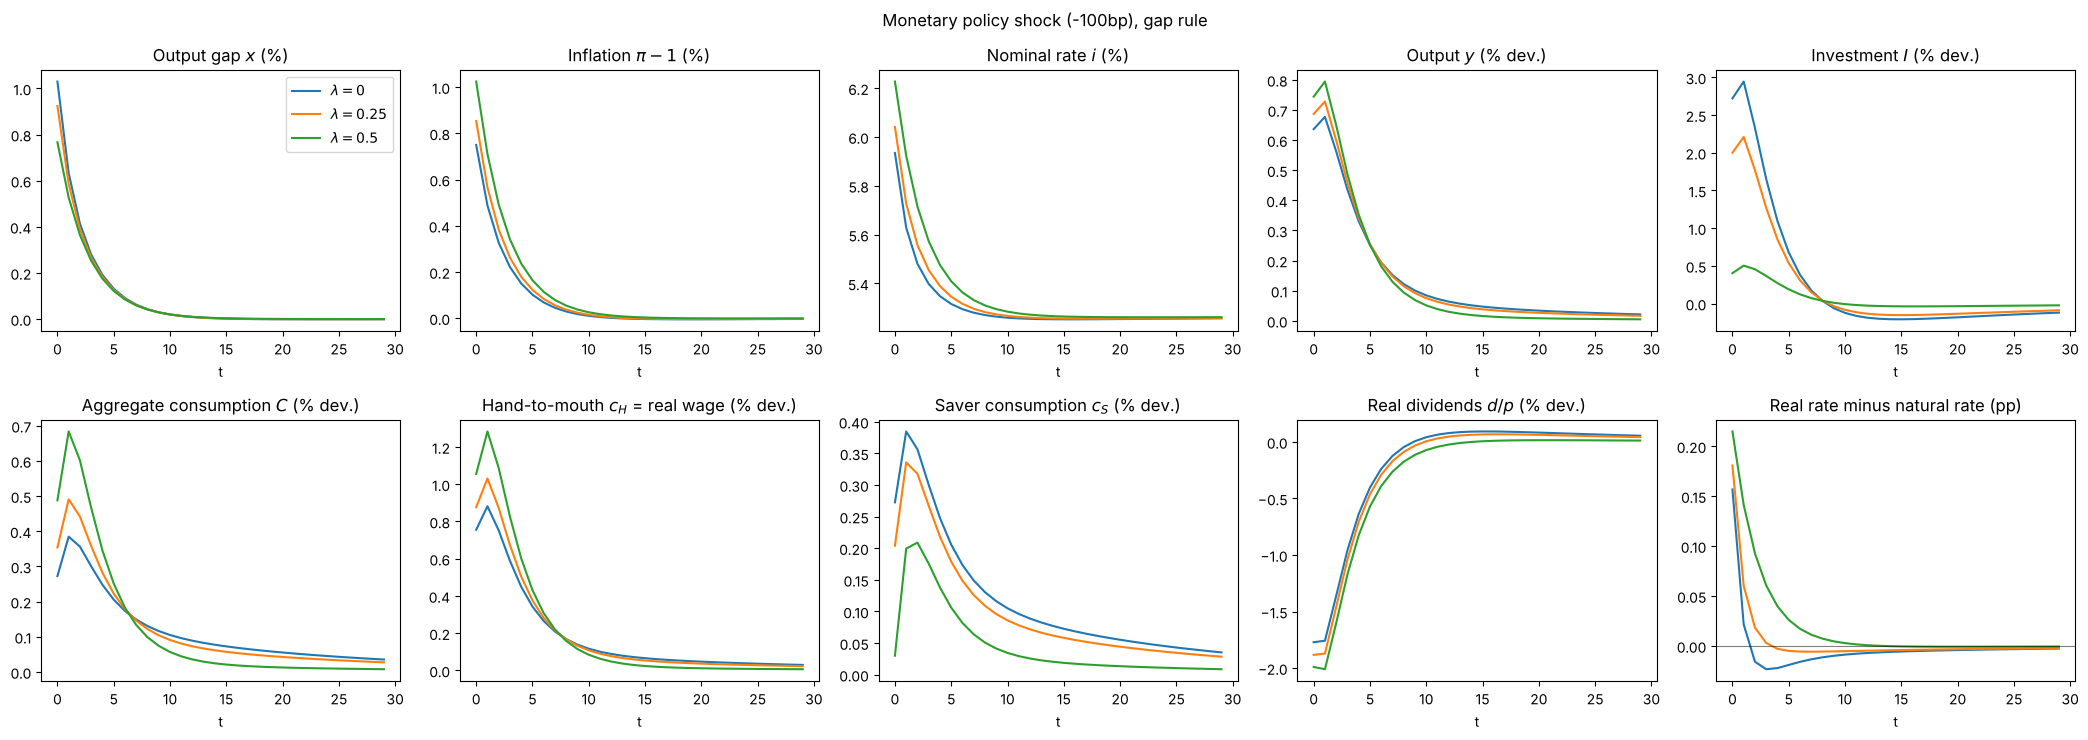

In [11]:
def plot_tank(econs, labels, refs, naturals, t_max=30, title=None):
    # refs: each economy's no-shock natural run (for % deviations); naturals: flexible run with the same shock
    fig, ax = plt.subplots(2, 5, figsize=(21, 7.5))
    pct = lambda key: (lambda e, ref: 100 * (e[key] / ref[key][:len(e[key])] - 1))
    series = [('Output gap $x$ (%)', lambda e, ref: 100 * e['gap']),
              (r'Inflation $\pi - 1$ (%)', lambda e, ref: 100 * (e['pi'] - 1)),
              ('Nominal rate $i$ (%)', lambda e, ref: 100 * e['i']),
              ('Output $y$ (% dev.)', pct('y')),
              ('Investment $I$ (% dev.)', pct('I')),
              ('Aggregate consumption $C$ (% dev.)', pct('c')),
              ('Hand-to-mouth $c_H$ = real wage (% dev.)', pct('c_H')),
              ('Saver consumption $c_S$ (% dev.)', pct('c_S')),
              ('Real dividends $d/p$ (% dev.)', lambda e, ref: 100 * (e['div'] / e['p'] / (ref['div'] / ref['p']) - 1)),
              ('Real rate minus natural rate (pp)', None)]
    for j, (a_, (ttl, fn)) in enumerate(zip(ax.flat, series)):
        for e, lab, ref, nat in zip(econs, labels, refs, naturals):
            v = 100 * (e['r_real'] - nat['r_real']) if fn is None else fn(e, ref)
            a_.plot(v[:t_max], label=lab)
        a_.set_title(ttl)
        a_.set_xlabel('t')
    ax.flat[-1].axhline(0, color='k', lw=0.8, alpha=0.5)
    ax.flat[0].legend()
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


mon = {lam: run_tank(nats[lam], nu=nu, lam=lam, verbose=False, **kw)[1] for lam in lams}
labels = [rf'$\lambda = {lam:g}$' for lam in lams]
plot_tank([mon[l] for l in lams], labels, [nats[l] for l in lams], [nats[l] for l in lams],
          title='Monetary policy shock (-100bp), gap rule')

### Step 1: the representative-agent economy

#### How the policy rule responds

The shock cuts the rule's intercept by one percentage point. But the nominal rate the rule sets also responds to what the shock does to inflation and the output gap. Splitting the nominal rate at $t = 0$ into its three terms:

In [12]:
s_tank = {lam: get_settings(lam=lam, **kw) for lam in lams}


def impact(e, ref, key):
    return 100 * (e[key][0] / ref[key][0] - 1)


def rule_terms(e, ref, s):
    # log(1+i_0) - log(1+r^n_0) = nu_0 + phi_pi log(pi_0) + phi_x x_0, in percentage points
    return (100 * nu[0], 100 * s.phi_pi * np.log(e['pi'][0]), 100 * s.phi_x * e['gap'][0],
            100 * (np.log(1 + e['i'][0]) - np.log(1 + ref['r_real'][0])))


e, ref, s_ = mon[0.0], nats[0.0], s_tank[0.0]
sh, inf_term, gap_term, total = rule_terms(e, ref, s_)
print('lambda = 0, nominal rate at t = 0 relative to the natural rate (pp)')
print(f'  shock                               {sh:+.2f}')
print(f'  inflation: 1.5 x {100 * np.log(e["pi"][0]):.2f}               {inf_term:+.2f}')
print(f'  output gap: 0.5 x {100 * e["gap"][0]:.2f}              {gap_term:+.2f}')
print(f'  total                               {total:+.2f}   (as a level: {100 * (e["i"][0] - ref["r_real"][0]):+.2f})')

lambda = 0, nominal rate at t = 0 relative to the natural rate (pp)
  shock                               -1.00
  inflation: 1.5 x 0.75               +1.12
  output gap: 0.5 x 1.03              +0.51
  total                               +0.64   (as a level: +0.67)


The shock cuts the rate by 1pp. But the expansion pushes inflation up by about 0.75pp and the gap up by about 1%, and the rule responds to both. The coefficient $\phi_\pi = 1.5$ is above one on purpose, so that rates rise more than one-for-one with inflation. That is the stabilising feature of the rule, and it is why the net effect on impact is a nominal rate **about 0.67pp above** the natural rate. The causality runs from the shock to a boom, from the boom to inflation, and from inflation to a rate rise. Higher rates are not causing the inflation.

Without the inflation and gap responses, the rate would simply have fallen by 1pp. The shock is the rule being more accommodating than usual at any given inflation rate, and that is what sets off the boom.

#### What happens in the economy

In [13]:
def bundle_rate(e):
    # real interest rate in units of the household's consumption-leisure bundle: (1+i_t) p_u,t / p_u,t+1 - 1
    return (1 + e['i']) * e['p_u'][:-1] / e['p_u'][1:] - 1


def saver_split(e, ref, s):
    # dln c_S = dln u_S (intertemporal) + (1-a) dln(w/p) (consumption-leisure mix)
    return (100 * np.log(e['c_S'][0] / ref['c_S'][0]), 100 * np.log(e['u'][0] / ref['u'][0]),
            100 * (1 - s.a) * np.log(e['real_w'][0] / ref['real_w'][0]))


real_div = lambda e, ref: 100 * (e['div'][0] / e['p'][0] / (ref['div'][0] / ref['p'][0]) - 1)
real_pks = lambda e, ref: 100 * (e['p_ks'][0] / e['p'][0] / (ref['p_ks'][0] / ref['p'][0]) - 1)

dc, du, dw = saver_split(e, ref, s_)
print('lambda = 0, responses at t = 0 (% deviation from steady state unless stated)')
print(f'  firms:       real marginal cost {e["mc"][0]:.4f}, markup {-100 * np.log(e["mc"][0]):+.2f}%, '
      f'real wage {impact(e, ref, "real_w"):+.2f}, real dividends {real_div(e, ref):+.2f}')
print(f'  households:  consumption {dc:+.2f} = intertemporal {du:+.2f} + consumption-leisure mix {dw:+.2f};  hours {impact(e, ref, "n"):+.2f}')
print(f'  real rates:  goods real rate vs natural: t=0 {100 * (e["r_real"][0] - ref["r_real"][0]):+.2f}, '
      f'cumulative {100 * np.sum(e["r_real"] - ref["r_real"]):+.2f} pp;  bundle real rate cumulative '
      f'{100 * np.sum(bundle_rate(e) - ref["r_real"]):+.2f} pp')
print(f'  investment:  real rental price of capital {real_pks(e, ref):+.2f}, Tobin q {e["q"][0] / e["p"][0]:.4f}, '
      f'investment {impact(e, ref, "I"):+.2f}')
print(f'  output:      {impact(e, ref, "y"):+.2f}')

lambda = 0, responses at t = 0 (% deviation from steady state unless stated)
  firms:       real marginal cost 1.0242, markup -2.39%, real wage +0.76, real dividends -1.77
  households:  consumption +0.27 = intertemporal -0.18 + consumption-leisure mix +0.45;  hours +0.96
  real rates:  goods real rate vs natural: t=0 +0.16, cumulative -0.10 pp;  bundle real rate cumulative +0.37 pp
  investment:  real rental price of capital +3.07, Tobin q 1.0027, investment +2.72
  output:      +0.64


**Firms.** Demand rises, but prices are sticky, so firms meet the extra demand by producing more. Real marginal cost rises above one, and the markup is squeezed about 2.4% below what firms want. This is what generates inflation: firms raise prices gradually to restore their markups. A squeezed markup means the real wage rises, by more than output, and real profits fall.

**Households.** The household's consumption rises 0.27%, but not for the reason a textbook would give. The household chooses a bundle of consumption and leisure, $u = c^a l^{1-a}$, and its consumption demand is $c = a\,(p_u/p)\,u$, where $p_u$ is the price of the bundle. Leisure in the bundle is priced at the wage, so the change in consumption splits into two parts:

$$
\Delta \ln c = \underbrace{\Delta \ln u}_{\text{intertemporal}} + \underbrace{(1-a)\,\Delta \ln (w/p)}_{\text{consumption–leisure mix}}
$$

- **Intertemporal: negative.** The Euler equation is on the bundle, so the interest rate that matters to the household is the real rate in bundle units, $(1 + i_t)\, p_{u,t}/p_{u,t+1}$. The real wage is high on impact and falling back, so the bundle is getting cheaper over time, which makes this rate higher than the goods real rate. Cumulatively it is about 0.37pp above its natural level. In the units the household cares about, policy is **tight**, and the household buys less of the bundle today.
- **Consumption–leisure mix: positive and larger.** A higher real wage makes leisure more expensive, so the household works more and shifts its spending from leisure to goods.

So the rise in consumption is driven by the higher wage, not by lower real rates.

**Investment.** The goods real rate is above its natural level on impact but slightly below it after that, about neutral overall. What drives investment is the rise in marginal cost: it raises the value of capital's marginal product, and so the real rental price of capital, by about 3%. Tobin's $q$ rises above one and investment rises about 2.7%.

**Output** rises about 0.6%. Consumption and investment add roughly equal amounts, and a further part of the rise is goods used up by firms in changing their prices: delivered output $y_t$ includes the price-adjustment cost.

#### A note on preferences

The split above comes from the Cobb-Douglas bundle $c^a l^{1-a}$, in which consumption and leisure are not separable, so the wage moves consumption directly. Most RANK and HANK work, including Kaplan, Moll and Violante (2018), uses preferences that are separable in consumption and hours. There the Euler equation is on consumption itself, the goods real rate is the right intertemporal price, and the "direct" effect of interest rates on consumption is what a representative agent would show. Comparisons with that literature should keep this difference in mind.

### Step 2: adding hand-to-mouth households

In [14]:
print('quantities at t = 0 (% deviation from steady state)')
print(f'{"":10s}{"output":>8s}{"C":>7s}{"from H":>8s}{"c_H=w/p":>9s}{"c_S":>7s}{"=interp.":>10s}{"+mix":>7s}'
      f'{"n_S":>7s}{"div/p":>7s}{"I":>7s}')
for lam in lams:
    e, ref, s_ = mon[lam], nats[lam], s_tank[lam]
    dC = e['c'][0] - ref['c'][0]
    share_H = lam * (e['c_H'][0] - ref['c_H'][0]) / dC
    dc, du, dw = saver_split(e, ref, s_)
    print(f'lam={lam:<6g}{impact(e, ref, "y"):8.2f}{impact(e, ref, "c"):7.2f}{100 * share_H:7.0f}%{impact(e, ref, "c_H"):9.2f}'
          f'{dc:7.2f}{du:10.2f}{dw:7.2f}{impact(e, ref, "n_S"):7.2f}{real_div(e, ref):7.2f}{impact(e, ref, "I"):7.2f}')

print('\nprices and policy')
print(f'{"":10s}{"infl.":>7s}{"gap":>7s}{"(mc-1)/gap":>12s}{"rule: infl.":>13s}{"gap":>7s}{"total":>8s}'
      f'{"goods stance":>14s}{"bundle stance":>15s}')
for lam in lams:
    e, ref, s_ = mon[lam], nats[lam], s_tank[lam]
    sh, inf_term, gap_term, total = rule_terms(e, ref, s_)
    print(f'lam={lam:<6g}{100 * (e["pi"][0] - 1):7.2f}{100 * e["gap"][0]:7.2f}{(e["mc"][0] - 1) / e["gap"][0]:12.2f}'
          f'{inf_term:+13.2f}{gap_term:+7.2f}{total:+8.2f}'
          f'{100 * np.sum(e["r_real"] - ref["r_real"]):+14.2f}{100 * np.sum(bundle_rate(e) - ref["r_real"]):+15.2f}')

quantities at t = 0 (% deviation from steady state)
            output      C  from H  c_H=w/p    c_S  =interp.   +mix    n_S  div/p      I
lam=0         0.64   0.27      0%     0.76   0.27     -0.18   0.45   0.96  -1.77   2.72
lam=0.25      0.69   0.35     55%     0.88   0.20     -0.32   0.52   1.48  -1.88   2.00
lam=0.5       0.74   0.49     97%     1.05   0.03     -0.60   0.63   2.85  -1.99   0.40

prices and policy
            infl.    gap  (mc-1)/gap  rule: infl.    gap   total  goods stance  bundle stance
lam=0        0.75   1.03        2.35        +1.12  +0.51   +0.64         -0.10          +0.37
lam=0.25     0.85   0.92        2.89        +1.27  +0.46   +0.74         +0.12          +0.67
lam=0.5      1.02   0.77        3.87        +1.53  +0.38   +0.91         +0.60          +1.25


"From H" is the share of the rise in aggregate consumption coming from hand-to-mouth households. Savers' consumption is split as in step 1, into the intertemporal part and the consumption–leisure mix. The rule columns are the inflation and gap terms of the nominal rate at $t = 0$; the shock term is always $-1.00$. The stance columns are cumulative real-rate gaps against the natural rate, in goods and in bundle units.

**Hand-to-mouth households spend the higher wage.** Their consumption equals $aH$ times the real wage, so it rises one-for-one with it. With $\lambda = 0.5$, they account for almost all of the rise in aggregate consumption, which is nearly twice as large as with $\lambda = 0$.

**The real wage rises more.** Hand-to-mouth hours are fixed, so only savers can supply the extra hours firms want. Aggregate labour supply is less elastic, and getting the same extra employment takes a bigger rise in the real wage. Real marginal cost rises more, markups are squeezed harder, and inflation is higher: about 1.0% rather than 0.75% with $\lambda = 0.5$. For the same reason, inflation rises more for each point of output gap.

**Policy tightens more.** The rule responds to the higher inflation, so its inflation term grows from about +1.1pp to +1.5pp. The measured gap is smaller, so its gap term shrinks a little, but on balance the nominal rate rises more. Measured in goods, the stance moves from roughly neutral to tight. Measured in bundle units, it is tight throughout and becomes much tighter.

**Savers absorb the tightening.** Savers are the only households who respond to interest rates. For them the intertemporal part of the consumption response grows from about $-0.2\%$ to $-0.6\%$, roughly cancelling the boost from the higher wage, so their consumption barely moves. Their dividends fall, and they work much more. Since savers also own the capital stock, the tighter rates fall on investment, which rises only 0.4% with $\lambda = 0.5$ against 2.7% with $\lambda = 0$.

**The result is a different boom, not a much bigger one.** Output rises only a little more with $\lambda = 0.5$. What changes is its make-up: consumption replaces investment, and the households driving it are the ones who spend their wages.

This is the mechanism Bilbiie (2008, 2020) identifies. Monetary policy is amplified when the income of hand-to-mouth households is more cyclical than aggregate income. Here sticky prices make wages rise faster than output while profits fall, so income shifts towards the households who spend all of it. In this model, though, the policy rule leans against the higher inflation, so the extra demand comes at the expense of investment rather than adding to output.

## A cost-push shock

Now raise firms' desired markup by 5%, $m_t = 0.05 \times 0.7^t$, as in Lecture 3. For each $\lambda$ we solve the flexible-price economy with the shock, which gives the natural allocation and the natural real rate under the shock, along with strict inflation targeting and the gap rule.

In [15]:
cpf = {lam: run_tank(nats[lam], markup=m, lam=lam, zeta_p=0.0, verbose=False, **kw)[1] for lam in lams}
cps = {lam: run_tank(nats[lam], markup=m, lam=lam, phi_x=0.0, phi_pi=1000.0, verbose=False, **kw)[1] for lam in lams}
cp = {lam: run_tank(nats[lam], markup=m, lam=lam, verbose=False, **kw)[1] for lam in lams}

for lam in lams:
    print(f'lam = {lam:<4g}: strict targeting vs flexible, max |n diff| = {np.max(np.abs(cps[lam]["n"] - cpf[lam]["n"])):.1e}')

lam = 0   : strict targeting vs flexible, max |n diff| = 2.4e-06
lam = 0.25: strict targeting vs flexible, max |n diff| = 1.7e-06
lam = 0.5 : strict targeting vs flexible, max |n diff| = 7.8e-07


As in the representative-agent economy, strict inflation targeting delivers the natural allocation for every $\lambda$. Zero inflation is still achieved by letting firms' markups rise through lower costs.

### The natural allocation: who bears the higher markup

In [16]:
print('natural allocation (flexible prices), % deviation at t = 0')
print(f'{"":8s}{"w/p = c_H":>11s}{"div/p":>8s}{"c_S":>7s}{"C":>7s}{"n_S":>7s}{"N":>7s}{"I":>7s}{"output":>8s}{"gap":>7s}')
for lam in lams:
    e, ref = cpf[lam], nats[lam]
    real_div = 100 * (e['div'][0] / e['p'][0] / (ref['div'][0] / ref['p'][0]) - 1)
    print(f'lam={lam:<4g}{impact(e, ref, "c_H"):11.2f}{real_div:8.2f}{impact(e, ref, "c_S"):7.2f}{impact(e, ref, "c"):7.2f}'
          f'{impact(e, ref, "n_S"):7.2f}{impact(e, ref, "n"):7.2f}{impact(e, ref, "I"):7.2f}{impact(e, ref, "y"):8.2f}{100 * e["gap"][0]:7.2f}')

natural allocation (flexible prices), % deviation at t = 0
          w/p = c_H   div/p    c_S      C    n_S      N      I  output    gap
lam=0         -1.72    3.53  -0.72  -0.72  -2.02  -2.02  -7.96   -1.38  -2.11
lam=0.25      -1.79    3.32  -0.56  -0.84  -2.80  -1.95  -6.28   -1.33  -1.72
lam=0.5       -1.92    2.99  -0.30  -1.02  -4.66  -1.84  -3.50   -1.25  -1.30


A higher markup is a transfer from wages to profits. The real wage falls, and with it hand-to-mouth consumption, by around 2%. Real dividends rise by about 3%, and savers, who receive them, cut their consumption only slightly. The cost of the shock falls on the households with no profit income.

Employment, by contrast, falls **less** as $\lambda$ rises. Hand-to-mouth hours don't respond to the lower wage, so only savers work less. Savers also cut their hours further because their dividend income has risen. The markup distorts the labour choice of only part of the workforce, so the **natural output gap shrinks** with $\lambda$, from about $-2.1\%$ to $-1.3\%$. Aggregate consumption falls **more**, because the households losing income are the ones who spend all of it. Investment falls less, because the extra profits go to savers, who save part of them.

So a larger hand-to-mouth share means a smaller fall in output and employment, a larger fall in consumption, and a more unequal distribution of the cost.

### Sticky prices and the gap rule

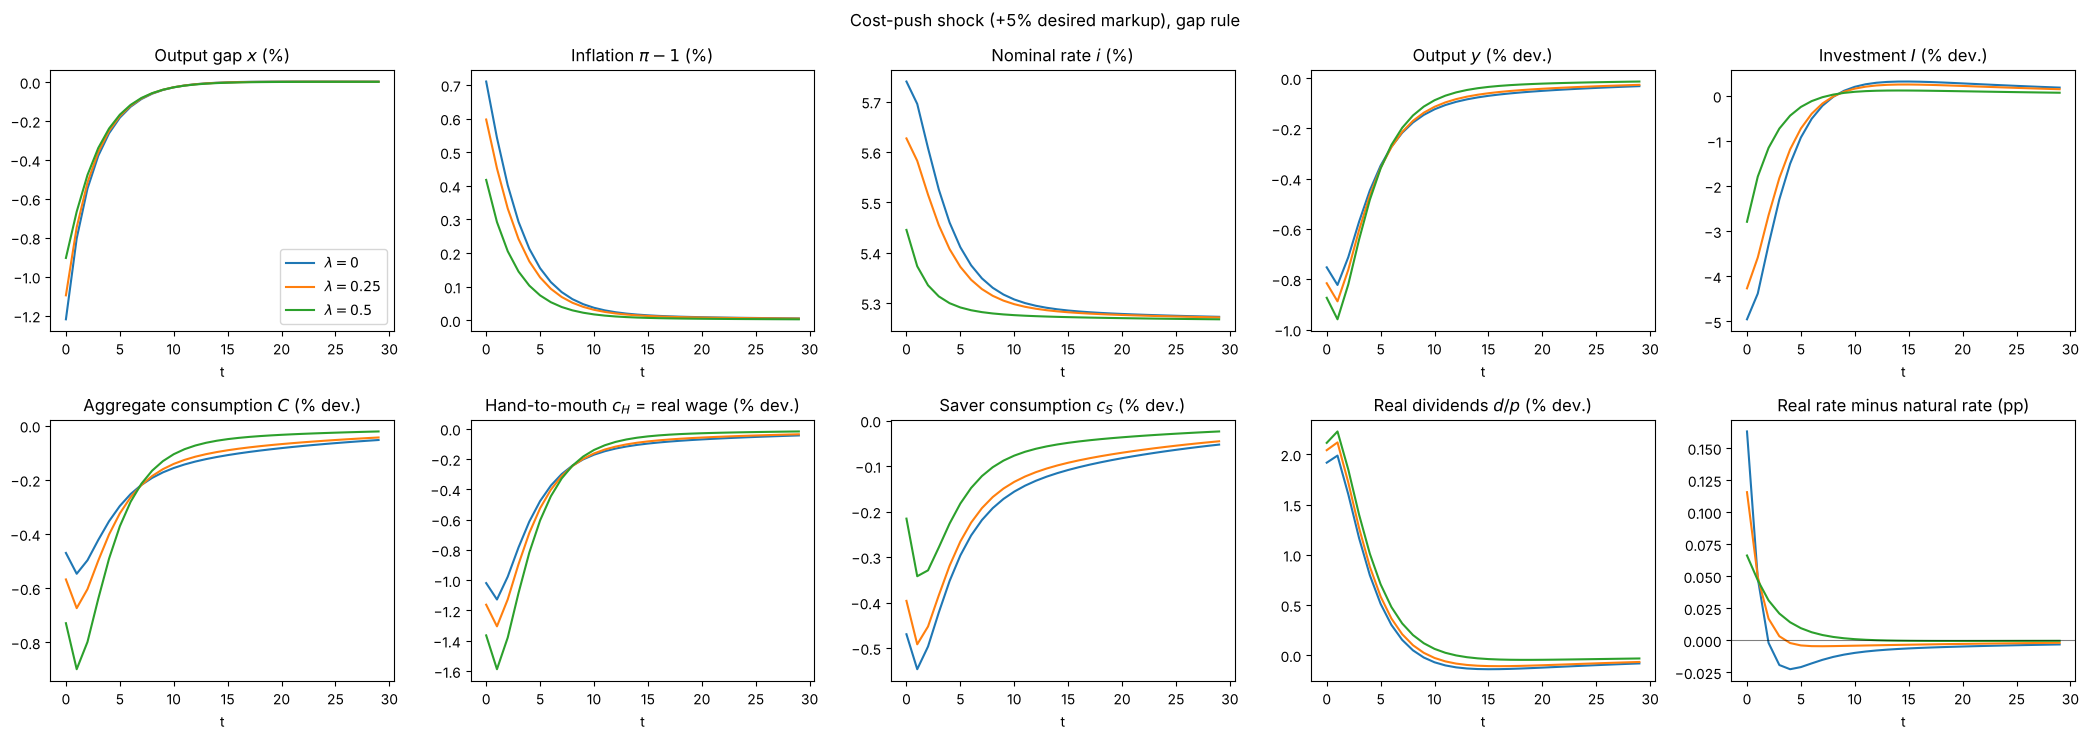

In [17]:
plot_tank([cp[l] for l in lams], labels, [nats[l] for l in lams], [cpf[l] for l in lams],
          title='Cost-push shock (+5% desired markup), gap rule')

In [18]:
print(f'{"":8s}{"gap":>7s}{"natural gap":>13s}{"infl.":>7s}{"stance":>8s}{"c_H gap rule":>14s}{"c_H strict":>12s}{"c_S gap rule":>14s}{"c_S strict":>12s}')
for lam in lams:
    e, ref, f = cp[lam], nats[lam], cpf[lam]
    print(f'lam={lam:<4g}{100 * e["gap"][0]:7.2f}{100 * f["gap"][0]:13.2f}{100 * (e["pi"][0] - 1):7.2f}'
          f'{100 * np.sum(e["r_real"] - f["r_real"]):+8.2f}'
          f'{impact(e, ref, "c_H"):14.2f}{impact(cps[lam], ref, "c_H"):12.2f}'
          f'{impact(e, ref, "c_S"):14.2f}{impact(cps[lam], ref, "c_S"):12.2f}')

            gap  natural gap  infl.  stance  c_H gap rule  c_H strict  c_S gap rule  c_S strict
lam=0     -1.22        -2.11   0.71   -0.09         -1.02       -1.72         -0.47       -0.72
lam=0.25  -1.10        -1.72   0.60   +0.06         -1.16       -1.80         -0.40       -0.56
lam=0.5   -0.90        -1.30   0.42   +0.19         -1.36       -1.93         -0.22       -0.30


Here the stance is measured against the natural real rate **under the shock**, the flexible-price run for the same $\lambda$, as in Lecture 3.

With sticky prices and the gap rule, both inflation and the measured gap are smaller as $\lambda$ rises. That's mostly because the natural gap is smaller: there is less of a slump to lean against. Output nonetheless falls slightly more, because hand-to-mouth consumption, which policy can only support through wages, falls more. With $\lambda = 0.25$ and $0.5$ the gap rule also ends up slightly **tighter** than the natural path. It responds to inflation as before, and its anchor, the no-shock natural rate, doesn't see the natural rate fall under the shock.

**The trade-off is now also about distribution.** Strict inflation targeting delivers the natural allocation, in which hand-to-mouth consumption falls by about 2% while savers' consumption barely moves. The gap rule accepts some inflation and holds demand up, which supports the real wage. Both types consume more than under strict targeting, but hand-to-mouth households gain several times as much: with $\lambda = 0.5$ their consumption falls by about 1.4% rather than 1.9%, while savers' consumption changes by less than a tenth of a percentage point. In a representative-agent economy, the choice between the gap rule and strict targeting is purely about aggregates. In a TANK economy it also decides how the cost of the shock is shared between workers and owners of capital.

## What TANK leaves out

The two-agent model captures the main HANK mechanism — high marginal propensities to consume make monetary transmission run through incomes — with a few extra equations in the existing system. But several features of HANK are missing:

- **Types are fixed.** No household ever moves between saver and hand-to-mouth status. In HANK, households drift towards and away from their borrowing limit as their income changes, so the hand-to-mouth share itself moves with the cycle.
- **No precautionary saving.** Savers face no income risk, so their marginal propensity to consume is low and constant. In HANK, even households with some wealth have fairly high MPCs, and a rise in uncertainty raises saving.
- **No government debt or fiscal rule.** Savers have only capital to hold, and the government's budget doesn't matter. In HANK, liquid government debt is what households save in, and how fiscal policy responds to a monetary shock matters a great deal for its effect.
- **Who receives profits is assumed, not derived.** The amplification above relies on all profits going to savers. If hand-to-mouth households received some profits, or if profits were less countercyclical, the amplification would shrink and could reverse (Bilbiie, 2020).

A full HANK model would replace the two types with a distribution of households, solved by iterating policy functions backwards and the distribution forwards. That gives a household block that maps paths of interest rates, wages and transfers into aggregate consumption and saving. The rest of the stacked system in this lecture, and the Newton solver, would carry over.

## References

- Bilbiie, F. O. (2008). Limited asset markets participation, monetary policy and (inverted) aggregate demand logic. *Journal of Economic Theory*, 140(1), 162–196.
- Bilbiie, F. O. (2020). The New Keynesian cross. *Journal of Monetary Economics*, 114, 90–108.
- Campbell, J. Y. and Mankiw, N. G. (1989). Consumption, income, and interest rates: reinterpreting the time series evidence. *NBER Macroeconomics Annual*, 4, 185–216.
- Galí, J., López-Salido, J. D. and Vallés, J. (2007). Understanding the effects of government spending on consumption. *Journal of the European Economic Association*, 5(1), 227–270.
- Kaplan, G., Moll, B. and Violante, G. L. (2018). Monetary policy according to HANK. *American Economic Review*, 108(3), 697–743.